# Validation of the compositional decipherment (glyph → Hebrew)

Five independent tests to determine whether the compositional mapping (166 glyphs → ~30 Hebrew characters) is linguistically significant or a trivial degeneration.

**Warning signs of the current mapping:**
- Severe many-to-one collapse: ש ← 17 glyphs, ר ← 15, ו ← 13
- Mean confidence 27.8%, median 11.5% (130/166 glyphs below 40%)
- The reconstruction shows שמר repeating ~10 times in the first 34 words

**Tests:**
1. Collapse coherence (structured or degenerate?)
2. N-gram realism (trigrams closer to Hebrew than random shuffles?)
3. Hebrew roots (consonantal skeletons match triliteral roots?)
4. Cardinality constraint (does the score survive limiting glyphs/char?)
5. Label analysis (do labels produce plausible Hebrew words?)


In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, io, os, tarfile, json, warnings
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy import stats as sp_stats
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# ── Colours ──
COLOR_ONSET   = '#1565C0'
COLOR_NUCLEAR = '#2E7D32'
COLOR_CODA    = '#F57F17'
COLOR_FREE    = '#757575'

LANG_COLORS = {
    'Voynich': '#E53935', 'Turkish': '#6D4C41', 'Finnish': '#D81B60',
    'Latin': '#4CAF50', 'Hebrew': '#2196F3', 'Arabic': '#FF9800',
}
ROLE_COLORS = {'C': '#1565C0', 'V': '#E53935', '?': '#9E9E9E'}

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

print('Imports OK')

Imports OK


In [ ]:
# ── Cell 2: Reused functions from compositional notebook ──────

# ── Cell 2: Reused functions from Bayesian notebook ──────────

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


# ── Download functions ──

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras


print('Reused functions loaded OK')


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    """Classifies glyphs by their positional role within classified syllables.

    For each glyph, counts in how many onset/nuclear/coda/free syllables it appears,
    and in which position within the syllable (onset/medial/coda).

    Returns:
        glyph_role: dict[str, str] — glifo → 'C' / 'V' / '?'
        glyph_stats: dict[str, dict] — statistics detalladas
    """
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)

    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1

    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }

    return glyph_role, glyph_stats


# ── Cell 4: Core functions — CharLM, GlyphMappingState, scoring, EM, MCMC ──

# ═══════════════════════════════════════════════════════════════
# 1.Character language model (trigram with Witten-Bell)
# ═══════════════════════════════════════════════════════════════

class CharLM:
    """LM of trigrams at the character level, with Witten-Bell smoothing."""

    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        """words: list[list[str]] — words as character lists."""
        BOS = '<w>'
        EOS = '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        """Log2-prob with backoff Witten-Bell: trigram → bigram → unigram."""
        # Trigram
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                # Backoff weight
                lambda_bo = tri_seen / (tri_total + tri_seen)
                # Bigram backoff
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            # No trigram context, backoff to bigram
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                # Unigram only
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        """Log2-probability of a word (list of characters)."""
        BOS = '<w>'
        EOS = '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        """Mean perplexity over a corpus."""
        total_lp = 0.0
        total_n = 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1  # +1 for EOS
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ═══════════════════════════════════════════════════════════════
# 2.Status mapping glyph → character (many-to-one)
# ═══════════════════════════════════════════════════════════════

class GlyphMappingState:
    """Mapping of Voynich glyphs to candidate language characters.

    Unlike MappingState (bijective, syllable→syllable),
    este mapping es many-to-one: varios glifos pueden mapear al mismo character.
    """

    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        """Propose change: assign new character to a random glyph."""
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)

        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars

        new.mapping[glyph] = rng.choice(candidates)
        return new

    def apply_word(self, word_glyphs):
        """Map word: [g1, g2, g3] → [c1, c2, c3]."""
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


# ═══════════════════════════════════════════════════════════════
# 3. Scoring functions
# ═══════════════════════════════════════════════════════════════

def score_char_lm(mapping, words, char_lm, sample_size=3000):
    """LM score: mean log-prob of mapped words under CharLM."""
    rng = np.random.default_rng(0)
    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        sample = [words[i] for i in idx]
    else:
        sample = words
    mapped = [mapping.apply_word(w) for w in sample]
    return np.mean([char_lm.log_prob(w) for w in mapped])


def score_positional(mapping, glyph_role, char_role):
    """Positional consistency score: % of glyphs whose role matches."""
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_total_comp(mapping, words, char_lm, glyph_role, char_role,
                     w_lm=2.0, w_pos=0.5):
    """Score total = w_lm * score_lm + w_pos * score_positional."""
    s_lm = score_char_lm(mapping, words, char_lm)
    s_pos = score_positional(mapping, glyph_role, char_role)
    return w_lm * s_lm + w_pos * s_pos, {'lm': s_lm, 'pos': s_pos}


def score_total_comp_fast(mapping, words_sample, char_lm, glyph_role, char_role,
                          w_lm=2.0, w_pos=0.5):
    """Score total fast (no undersampling — you already receive sample)."""
    mapped = [mapping.apply_word(w) for w in words_sample]
    s_lm = np.mean([char_lm.log_prob(w) for w in mapped])
    s_pos = score_positional(mapping, glyph_role, char_role)
    return w_lm * s_lm + w_pos * s_pos


# ═══════════════════════════════════════════════════════════════
# 4. Initialization by frequency + class
# ═══════════════════════════════════════════════════════════════

def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    """Assign by frequency within each C/V class."""
    # Frequencies of glyphs
    gf = Counter(g for p in palabras for g in p)
    # Frequencys de characters
    cf = Counter(c for w in target_words for c in w)

    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


# ═══════════════════════════════════════════════════════════════
# 5. EM compositional
# ═══════════════════════════════════════════════════════════════

def em_glyph_decipher(words, char_lm, glyph_role, char_role,
                      initial_state, n_iter=50, patience=10,
                      sample_size=3000, changes_per_iter=200):
    """EM: propose glyph changes, accept if score improves."""
    rng = np.random.default_rng(42)

    # Subsample for fast scoring
    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        words_sample = [words[i] for i in idx]
    else:
        words_sample = words

    best_state = initial_state
    best_score = score_total_comp_fast(best_state, words_sample, char_lm,
                                       glyph_role, char_role)
    scores_history = [best_score]
    no_improve = 0

    for it in range(n_iter):
        improved = False
        for _ in range(changes_per_iter):
            proposal = best_state.propose_change(rng, constrained=True)
            prop_score = score_total_comp_fast(proposal, words_sample, char_lm,
                                               glyph_role, char_role)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                improved = True

        scores_history.append(best_score)
        print(f'    iter {it+1}: score={best_score:.4f}' + (' *' if improved else ''))

        if improved:
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  EM converged at iteration {it+1}')
                break

    return best_state, scores_history

print('Core functions loaded OK: CharLM, GlyphMappingState, scoring, EM, MCMC')

Funciones reutilizadas cargadas OK
Funciones core cargadas OK: CharLM, GlyphMappingState, scoring, EM, MCMC


In [ ]:
# ── Cell 3: Load results + corpus ──────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

# 1. Parse Voynich
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
print(f'Voynich: {len(palabras):,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')

# 2. Segmentation syllabic + classification de glyphs
M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, _ = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)
glyph_freq = Counter(corpus_plano)

# 3. Load compositional results
with open('composicional_resultados.json', 'r') as f:
    comp_results = json.load(f)

mapping_heb = comp_results['mapping']['Hebreo']
posterior_heb = comp_results['posterior']['Hebreo']
ranking_comp = comp_results['ranking']
print(f'\nHebrew mapping: {len(mapping_heb)} glyphs mapped')

# Per-glyph confidence
confidences = {}
for g, post_dict in posterior_heb.items():
    confidences[g] = max(post_dict.values()) if post_dict else 0.0
mean_conf = np.mean(list(confidences.values()))
median_conf = np.median(list(confidences.values()))
n_high = sum(1 for c in confidences.values() if c >= 0.70)
n_low = sum(1 for c in confidences.values() if c < 0.40)
print(f'Trust: mean={mean_conf:.1%}, median={median_conf:.1%}, '
      f'>=70%: {n_high}, <40%: {n_low}')

# Collapse: how many glyphs por char Hebrew
collapse = defaultdict(list)
for g, c in mapping_heb.items():
    collapse[c].append(g)
collapse_counts = {c: len(gs) for c, gs in collapse.items()}
print(f'\n Collapse many-to-one:')
for c, cnt in sorted(collapse_counts.items(), key=lambda x: -x[1])[:5]:
    print(f'  {c} <- {cnt} glyphs: {collapse[c][:8]}...')

# 4. Load syllabic results (for comparison)
with open('bayesiano_silabico_resultados.json', 'r') as f:
    syl_results = json.load(f)
print(f'\nSyllabic results loaded: ranking top={syl_results["ranking"][0]["language"]}')

# 5. Download Hebrew + CharLM
hebrew_words = descargar_hebreo()
char_lm_heb = CharLM(order=3)
char_lm_heb.fit(hebrew_words)
ppx_native = char_lm_heb.perplexity(hebrew_words[:5000])
print(f'CharLM Hebrew: vocab={len(char_lm_heb.vocab)}, native PPX={ppx_native:.2f}')

# 6. Build char_role for Hebrew
HEBREW_VOWELS = set('אוי')
HEBREW_CONSONANTS = set('בגדהזחטכלמנסעפצקרשת')
SOFIT = set('ךםןףץ')
char_role_heb = {}
for c in char_lm_heb.vocab:
    if c in ('<w>', '</w>'):
        continue
    if c in HEBREW_VOWELS:
        char_role_heb[c] = 'V'
    elif c in HEBREW_CONSONANTS or c in SOFIT:
        char_role_heb[c] = 'C'
    else:
        char_role_heb[c] = '?'

# 7. Rebuild GlyphMappingState
target_chars_heb = sorted(set(mapping_heb.values()))
state_heb = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
state_heb.set_mapping(mapping_heb)

score_real, details_real = score_total_comp(state_heb, palabras, char_lm_heb,
                                            glyph_role, char_role_heb)
print(f'\nReal score of Hebrew mapping: {score_real:.4f} (LM={details_real["lm"]:.4f}, pos={details_real["pos"]:.2f})')
print('\nFull charge.')

Voynich: 37,087 words, 157,254 tokens, 166 glyphs

Mapping Hebreo: 166 glyphs mapeados
Confianza: media=27.8%, mediana=11.5%, >=70%: 26, <40%: 130

Colapso many-to-one:
  ש <- 17 glyphs: ['B1', 'Q1', 'Q2', 'C2', 'Ba', 'P1', 'U2', 'U1']...
  ר <- 15 glyphs: ['C1', 'G1', 'F1', 'B3', 'F3', 'G3', 'B4', 'E2']...
  ו <- 13 glyphs: ['P2', 'E1', 'Z1', 'Qa', 'F2', 'Xf', 'Km', 'Ee']...
  ע <- 10 glyphs: ['B2', 'B5', 'W1', 'V2', 'G2', 'U6', 'Tm', 'Uh']...
  מ <- 9 glyphs: ['A1', 'A3', 'Aa', 'M1', 'U5', 'Cm', 'Ra', 'Wc']...

Resultados syllabics cargados: ranking top=Hebreo
  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 words
CharLM Hebreo: vocab=29, PPX nativa=7.60

Score real del mapping Hebreo: -39.8973 (LM=-20.1986, pos=1.00)

Carga completa.


## Test 1: Collapse coherence

**Question**: Do glyphs mapping to the same Hebrew character have DIFFERENT positional distributions (functional structure) or SIMILAR ones (degeneration)?

If the collapse is linguistically motivated, glyphs grouped under the same character should represent variants of the same phoneme in different contexts (e.g., initial shin vs. final shin). If degenerate, the glyphs would be interchangeable.

**Method**: For each Hebrew character with ≥3 glyphs, measure positional diversity (mean pairwise JSD). Compare against 200 random groupings of the same size (permutation test).


Test 1: Coherencia del colapso
Char  N glifos JSD real JSD null z-score  Veredicto
   ז         3   0.7900   0.5397    1.72 STRUCTURED
   פ         5   0.6766   0.5160    1.67 STRUCTURED
   ד         5   0.6662   0.5160    1.56 STRUCTURED
   ב         5   0.6456   0.5160    1.35  AMBIGUOUS
   ן         7   0.6032   0.5228    1.15  AMBIGUOUS
   ה         3   0.6286   0.5397    0.61  AMBIGUOUS
   י         7   0.5649   0.5228    0.60  AMBIGUOUS
   א         8   0.5255   0.5184    0.12  AMBIGUOUS
   ג         7   0.5071   0.5228   -0.22  AMBIGUOUS
   ץ         7   0.5017   0.5228   -0.30  AMBIGUOUS
   ע        10   0.5041   0.5212   -0.36  AMBIGUOUS
   כ         7   0.4892   0.5228   -0.48  AMBIGUOUS
   ף         3   0.4700   0.5397   -0.48  AMBIGUOUS
   ו        13   0.4916   0.5163   -0.59  AMBIGUOUS
   ת         9   0.4889   0.5192   -0.60  AMBIGUOUS
   ח         9   0.4854   0.5192   -0.67  AMBIGUOUS
   מ         9   0.4255   0.5192   -1.86 DEGENERATE
   צ         4   0.1546   0.5187 

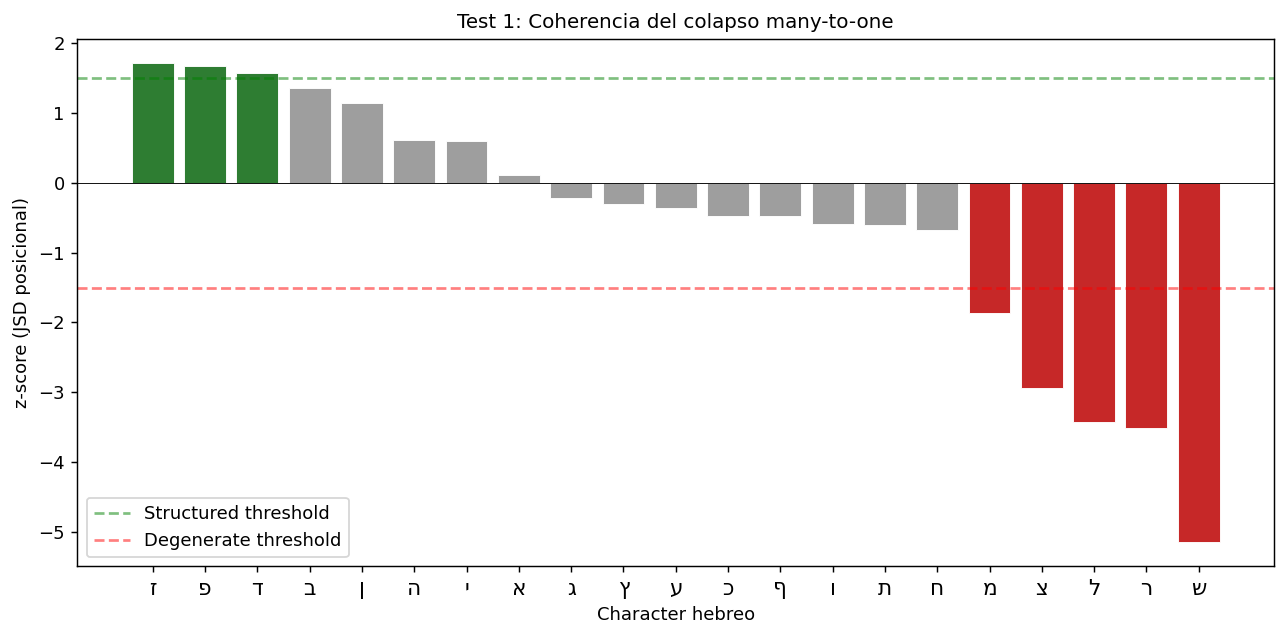

Guardado: aux_docs/validation_colapso.png


In [ ]:
# ── Cell 5: Test 1 — Collapse coherence ─────────────────────────────

def positional_distribution(glyph, palabras):
    """Positional distribution of a glyph: [pct_start, pct_middle, pct_end]."""
    counts = np.array([0.0, 0.0, 0.0])  # onset, medial, coda
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5
                    counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    if total == 0:
        return np.array([1/3, 1/3, 1/3])
    return counts / total


def collapse_coherence_test(mapping, palabras, n_shuffles=200, min_group_size=3):
    """Many-to-one collapse coherence test.

    For each Hebrew char with >= min_group_size glyphs:
    -Calculate pairwise mean JSD from positional distributions
    -Compare with random groupings of the same size
    -z-score > 1.5 = 'STRUCTURED', < -1.5 = 'DEGENERATE', else 'AMBIGUOUS'
    """
    groups = defaultdict(list)
    for g, c in mapping.items():
        groups[c].append(g)

    all_glyphs = list(mapping.keys())

    # Pre-calculate positional distributions
    pos_dists = {}
    for g in all_glyphs:
        pos_dists[g] = positional_distribution(g, palabras)

    results = {}
    for char, glyphs in groups.items():
        if len(glyphs) < min_group_size:
            continue

        pairs = list(combinations(glyphs, 2))
        if not pairs:
            continue
        real_jsds = []
        for g1, g2 in pairs:
            d1 = pos_dists[g1] + 1e-10
            d2 = pos_dists[g2] + 1e-10
            real_jsds.append(jensenshannon(d1, d2))
        real_mean_jsd = np.mean(real_jsds)

        # Null distribution
        rng = np.random.default_rng(42)
        null_jsds = []
        for _ in range(n_shuffles):
            random_group = rng.choice(all_glyphs, size=len(glyphs), replace=False)
            null_pairs = list(combinations(random_group, 2))
            jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                    for g1, g2 in null_pairs]
            null_jsds.append(np.mean(jsds))

        null_mean = np.mean(null_jsds)
        null_std = np.std(null_jsds) if np.std(null_jsds) > 1e-10 else 1e-10
        z_score = (real_mean_jsd - null_mean) / null_std

        if z_score > 1.5:
            verdict = 'STRUCTURED'
        elif z_score < -1.5:
            verdict = 'DEGENERATE'
        else:
            verdict = 'AMBIGUOUS'

        results[char] = {
            'n_glyphs': len(glyphs),
            'glyphs': glyphs,
            'real_jsd': real_mean_jsd,
            'null_mean': null_mean,
            'null_std': null_std,
            'z_score': z_score,
            'verdict': verdict,
        }

    return results


# Execute
collapse_results = collapse_coherence_test(mapping_heb, palabras, n_shuffles=200)

# Table
rows = []
for char, res in sorted(collapse_results.items(), key=lambda x: -x[1]['z_score']):
    rows.append({
        'Char': char,
        'N glyphs': res['n_glyphs'],
        'JSD real': f'{res["real_jsd"]:.4f}',
        'JSD null': f'{res["null_mean"]:.4f}',
        'z-score': f'{res["z_score"]:.2f}',
        'Verdict': res['verdict'],
    })

df_collapse = pd.DataFrame(rows)
print('Test 1: Coherencia del colapso')
print('=' * 60)
print(df_collapse.to_string(index=False))
print()

n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
n_ambig = sum(1 for r in collapse_results.values() if r['verdict'] == 'AMBIGUOUS')
mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
print(f'Summary: STRUCTURED={n_struct}, DEGENERATE={n_degen}, AMBIGUOUS={n_ambig}')
print(f'Mean z-score: {mean_z:.2f}')

# Visualisation
fig, ax = plt.subplots(figsize=(10, 5))
chars = [c for c, _ in sorted(collapse_results.items(), key=lambda x: -x[1]['z_score'])]
z_scores = [collapse_results[c]['z_score'] for c in chars]
colors = ['#2E7D32' if z > 1.5 else '#C62828' if z < -1.5 else '#9E9E9E' for z in z_scores]
ax.bar(range(len(chars)), z_scores, color=colors, edgecolor='white', linewidth=0.5)
ax.set_xticks(range(len(chars)))
ax.set_xticklabels(chars, fontsize=12)
ax.axhline(1.5, color='green', linestyle='--', alpha=0.5, label='Structured threshold')
ax.axhline(-1.5, color='red', linestyle='--', alpha=0.5, label='Degenerate threshold')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('Character hebrew')
ax.set_ylabel('z-score (JSD positional)')
ax.set_title('Test 1: Coherence of many-to-one collapse')
ax.legend()
plt.tight_layout()
os.makedirs('aux_docs', exist_ok=True)
plt.savefig('images/validacion_colapso.png', bbox_inches='tight')
plt.show()
print('Saved: aux_docs/validation_colapso.png')

## Test 2: N-gram realism

**Question**: Does the mapped text have a trigram distribution closer to real Hebrew than random mappings?

If the mapping captures real linguistic structure, the trigrams of the mapped text should resemble those of Hebrew (Torah) more than those generated by random shuffles of the mapping.


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

Test 2: Realismo n-gram
JSD real vs Hebrew:      0.7528
JSD null media:          0.7686 +/- 0.0180
Percentile JSD (menor=mejor): 17.0%
Trigram entropy real:    6.01 bits
Trigram entropy null:    7.86 +/- 0.18 bits
Word-type diversity real: 1,093
Word-type diversity null: 1997 +/- 81

Veredicto: MARGINAL


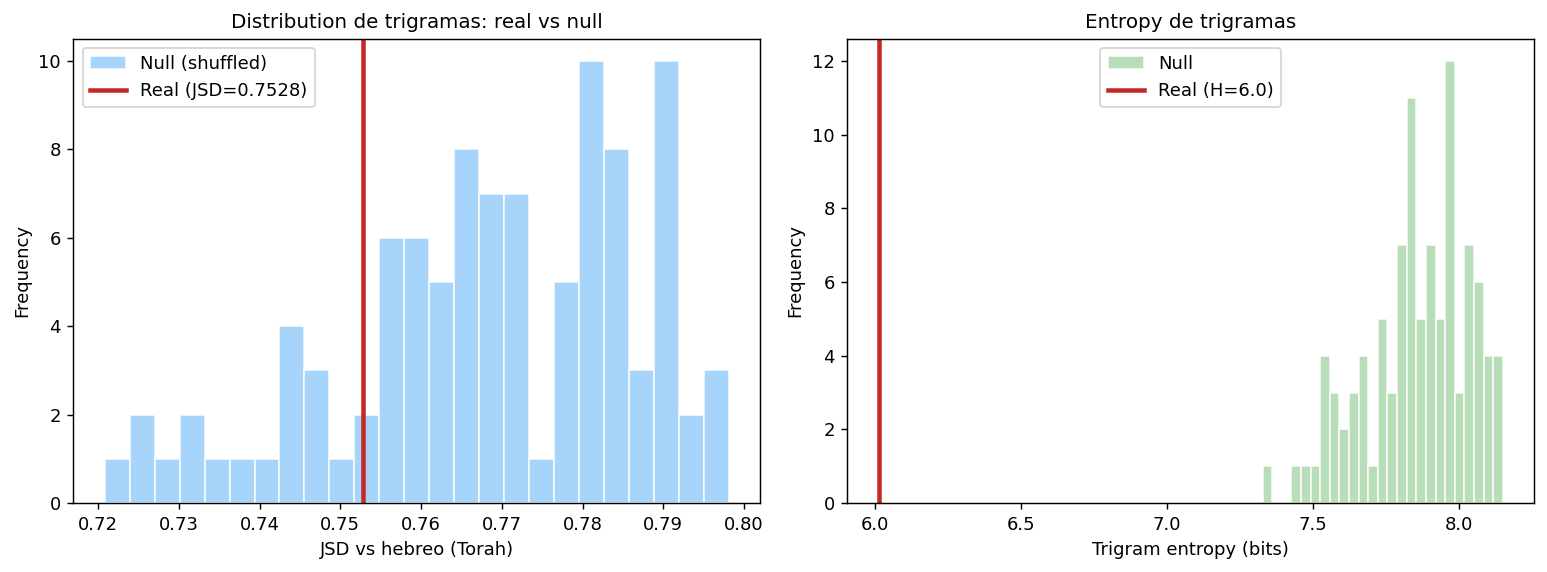

Guardado: aux_docs/validation_ngram.png


In [ ]:
# ── Cell 7: Test 2 — N-gram realism ─────────────────────────────────

def corpus_trigram_distribution(words):
    """Distribution of normalized trigrams of a corpus of words."""
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    if total == 0:
        return {}
    return {tri: cnt / total for tri, cnt in trigram_counts.items()}


def trigram_jsd(dist1, dist2):
    """JSD between two trigram distributions."""
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12
    q = q + 1e-12
    p = p / p.sum()
    q = q / q.sum()
    return float(jensenshannon(p, q))


def ngram_realism_test(mapping_state, palabras, hebrew_words, n_shuffles=100,
                       sample_size=5000):
    """N-gram realism test.

    JSD compares trigrams from mapped text vs real Hebrew.
    Null: random shuffles of the mapping.
    """
    rng = np.random.default_rng(42)

    # Reference distribution: Hebrew real
    heb_sample = hebrew_words[:sample_size] if len(hebrew_words) > sample_size else hebrew_words
    ref_dist = corpus_trigram_distribution(heb_sample)

    # Actual mapped text
    voynich_sample = palabras[:sample_size] if len(palabras) > sample_size else palabras
    mapped_real = [mapping_state.apply_word(w) for w in voynich_sample]
    real_dist = corpus_trigram_distribution(mapped_real)
    real_jsd = trigram_jsd(real_dist, ref_dist)

    # Word-type diversity
    real_types = len(set(''.join(w) for w in mapped_real))

    # Trigram entropy
    vals = np.array(list(real_dist.values()))
    vals = vals[vals > 0]
    real_entropy = -np.sum(vals * np.log2(vals))

    # Null: shuffled mappings
    null_jsds = []
    null_entropies = []
    null_diversities = []
    all_chars = list(set(mapping_state.mapping.values()))

    for _ in tqdm(range(n_shuffles), desc='Null shuffles'):
        shuffled_mapping = {}
        for g in mapping_state.mapping:
            shuffled_mapping[g] = rng.choice(all_chars)
        shuf_state = GlyphMappingState(mapping_state.voynich_glyphs,
                                        mapping_state.target_chars,
                                        mapping_state.glyph_role,
                                        mapping_state.char_role)
        shuf_state.set_mapping(shuffled_mapping)
        mapped_shuf = [shuf_state.apply_word(w) for w in voynich_sample]
        shuf_dist = corpus_trigram_distribution(mapped_shuf)
        null_jsds.append(trigram_jsd(shuf_dist, ref_dist))
        vals_s = np.array(list(shuf_dist.values()))
        vals_s = vals_s[vals_s > 0]
        null_entropies.append(-np.sum(vals_s * np.log2(vals_s)))
        null_diversities.append(len(set(''.join(w) for w in mapped_shuf)))

    # Percentile rank (lower JSD = better, so lower percentilee = better)
    percentile_jsd = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds]))

    return {
        'real_jsd': real_jsd,
        'null_jsds': null_jsds,
        'percentile_jsd': percentile_jsd,
        'real_entropy': real_entropy,
        'null_entropies': null_entropies,
        'real_diversity': real_types,
        'null_diversities': null_diversities,
    }


# Execute
ngram_results = ngram_realism_test(state_heb, palabras, hebrew_words, n_shuffles=100)

print('Test 2: N-gram Realism')
print('=' * 60)
print(f'JSD real vs Hebrew:      {ngram_results["real_jsd"]:.4f}')
print(f'JSD null media:          {np.mean(ngram_results["null_jsds"]):.4f} +/- {np.std(ngram_results["null_jsds"]):.4f}')
print(f'Percentile JSD (): {ngram_results["percentile_jsd"]:.1f}%')
print(f'Trigram entropy relesser=betteral:    {ngram_results["real_entropy"]:.2f} bits')
print(f'Trigram entropy null:    {np.mean(ngram_results["null_entropies"]):.2f} +/- {np.std(ngram_results["null_entropies"]):.2f} bits')
print(f'Word-type diversity real: {ngram_results["real_diversity"]:,}')
print(f'Word-type diversity null: {np.mean(ngram_results["null_diversities"]):.0f} +/- {np.std(ngram_results["null_diversities"]):.0f}')

if ngram_results['percentile_jsd'] <= 5:
    verdict_ngram = 'PASS'
elif ngram_results['percentile_jsd'] <= 20:
    verdict_ngram = 'MARGINAL'
else:
    verdict_ngram = 'FAIL'
print(f'\nVerdict: {verdict_ngram}')

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.hist(ngram_results['null_jsds'], bins=25, color='#90CAF9', edgecolor='white',
        alpha=0.8, label='Null (shuffled)')
ax.axvline(ngram_results['real_jsd'], color='#C62828', linewidth=2.5,
           linestyle='-', label=f'Real (JSD={ngram_results["real_jsd"]:.4f})')
ax.set_xlabel('JSD vs Hebrew (Torah)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of trigrams: real vs null')
ax.legend()

ax = axes[1]
ax.hist(ngram_results['null_entropies'], bins=25, color='#A5D6A7', edgecolor='white',
        alpha=0.8, label='Null')
ax.axvline(ngram_results['real_entropy'], color='#C62828', linewidth=2.5,
           linestyle='-', label=f'Real (H={ngram_results["real_entropy"]:.1f})')
ax.set_xlabel('Trigram entropy (bits)')
ax.set_ylabel('Frequency')
ax.set_title('Entropy of trigrams')
ax.legend()

plt.tight_layout()
plt.savefig('images/validacion_ngram.png', bbox_inches='tight')
plt.show()
print('Saved: aux_docs/validation_ngram.png')

## Test 3: Hebrew roots

**Question**: Do the consonantal skeletons of frequent words match real Hebrew triliteral roots?

Hebrew is a Semitic language with triliteral roots (3 consonants) that combine with vocalic patterns. If the mapping is correct, the consonants of the most frequent mapped words should match real roots from the Torah.

**Note**: This test has a high false positive rate due to wildcards (`*`), but a strong result (many distinct roots with good enrichment) would be significant.


In [ ]:
# ── Cell 9: Test 3 — Root matching ──────────────────────────────────

# ~100 triliteral roots most frequents de la Torah
HEBREW_ROOTS = {
    # Roots verbal more comunes
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    # Roots nominales frecuentes
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')


def extract_skeleton(mapped_word, confidences, conf_threshold=0.70,
                     glyph_word=None):
    """Extract consonantal skeleton with wildcards for low-confidence glyphs."""
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if glyph_word and i < len(glyph_word):
            g = glyph_word[i]
            conf = confidences.get(g, 0)
            if conf < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)


def match_skeleton_to_root(skeleton, root):
    """Match skeleton (with wildcards) against a root."""
    if len(skeleton) != len(root):
        return False
    for s, r in zip(skeleton, root):
        if s == '*':
            continue
        if s != r:
            return False
    return True


def root_matching(palabras, mapping, confidences, hebrew_roots,
                  conf_threshold=0.70, top_n=200):
    """Test de matching of Hebrew roots."""
    word_freq = Counter()
    for w in palabras:
        word_freq[tuple(w)] += 1

    top_words = word_freq.most_common(top_n)
    matches = []
    skeletons_seen = Counter()
    roots_matched = set()

    for word_tuple, freq in top_words:
        word_glyphs = list(word_tuple)
        mapped = [mapping.get(g, '?') for g in word_glyphs]
        skeleton = extract_skeleton(mapped, confidences, conf_threshold, word_glyphs)

        if len(skeleton) < 3:
            continue

        for i in range(len(skeleton) - 2):
            sub = skeleton[i:i+3]
            skeletons_seen[sub] += 1

            for root in hebrew_roots:
                if match_skeleton_to_root(sub, root):
                    roots_matched.add(root)
                    matches.append({
                        'word': ''.join(word_glyphs),
                        'mapped': ''.join(mapped),
                        'skeleton': skeleton,
                        'sub_skeleton': sub,
                        'root': root,
                        'freq': freq,
                        'n_wildcards': sub.count('*'),
                    })

    # Tasa esperada de match por azar
    n_roots = len(hebrew_roots)
    n_consonants = len(HEBREW_CONSONANTS_SET)
    unique_skeletons = len(skeletons_seen)
    n_wildcards_mean = np.mean([s.count('*') for s in skeletons_seen.keys()]) if skeletons_seen else 0
    expected_matches_per_skel = n_roots * (1 / n_consonants) ** max(3 - n_wildcards_mean, 0.5)
    expected_total = expected_matches_per_skel * unique_skeletons

    return {
        'matches': matches,
        'n_matches': len(matches),
        'n_distinct_roots': len(roots_matched),
        'roots_matched': roots_matched,
        'n_skeletons': unique_skeletons,
        'n_wildcards_mean': n_wildcards_mean,
        'expected_matches': expected_total,
        'enrichment': len(matches) / max(expected_total, 1),
    }


# Execute
root_results = root_matching(palabras, mapping_heb, confidences, HEBREW_ROOTS,
                              conf_threshold=0.70, top_n=200)

print('Test 3: Hebrew roots')
print('=' * 60)
print(f'Matches found: {root_results["n_matches"]}')
print(f'Roots distinct: {root_results["n_distinct_roots"]}')
print(f'Skeletons analyzed: {root_results["n_skeletons"]}')
print(f'Wildcards average per skeleton: {root_results["n_wildcards_mean"]:.2f}')
print(f'Matches random expected: {root_results["expected_matches"]:.1f}')
print(f'Enrichment ratio: {root_results["enrichment"]:.1f}x')
print(f'\nRoots found: {sorted(root_results["roots_matched"])}')

# Table top-30
if root_results['matches']:
    seen_words = set()
    rows = []
    for m in sorted(root_results['matches'], key=lambda x: -x['freq']):
        if m['word'] in seen_words:
            continue
        seen_words.add(m['word'])
        rows.append({
            'Word': m['word'],
            'Mapped': m['mapped'],
            'Skeleton': m['skeleton'],
            'Sub-esq': m['sub_skeleton'],
            'Root': m['root'],
            'Freq': m['freq'],
            'Wildcards': m['n_wildcards'],
        })
        if len(rows) >= 30:
            break
    print('\nTop-30 words with roots matched:')
    print(pd.DataFrame(rows).to_string(index=False))

if root_results['n_distinct_roots'] >= 5:
    verdict_roots = 'PROMISING'
elif root_results['n_distinct_roots'] >= 3:
    verdict_roots = 'WEAK'
else:
    verdict_roots = 'NEGATIVE'
print(f'\nVerdict: {verdict_roots}')

Test 3: Hebrew roots
Matches encontrados: 84
Roots distintas: 6
Esqueletos analizados: 45
Wildcards promedio por esqueleto: 0.22
Matches esperados por azar: 0.5
Enrichment ratio: 84.0x

Roots encontradas: ['חמר', 'עשה', 'שלח', 'שמע', 'שמר', 'שמש']

Top-30 words con roots matched:
     Palabra Mapeada Esqueleto Sub-esq Root  Freq  Wildcards
      B1A3G1     שמר       שמר     שמר  שמר   665          0
  D1A1Q1A3F1   למשמר     למשמר     שמר  שמר   271          0
  D1A1Q1A3G1   למשמר     למשמר     שמר  שמר   255          0
      B1A3C1     שמר       שמר     שמר  שמר   252          0
D1A1Q1K2B1A2  למשחשת    למש*שת     ש*ש  שמש   217          1
    A1Q1A3G1    משמר      משמר     שמר  שמר   200          0
  D1A1Q1A3B2   למשמע     למשמע     שמע  שמע   179          0
      B1A3B2     שמע       שמע     שמע  שמע   174          0
      B1A3F1     שמר       שמר     שמר  שמר   147          0
    A1Q2A3G1    משמר      משמר     שמר  שמר   147          0
  D1A1Q1A3C1   למשמר     למשמר     שמר  שמר   14

## Test 4: Cardinality constraint

**Question**: If we limit how many glyphs can map to the same character (K_max), does the score drop significantly?

A robust mapping should maintain a reasonable score even under cardinality constraints. If the score depends critically on concentrating 15–17 glyphs on a single character, it signals degeneration.



EM Constrained K_max=6
    iter 1: score=-63.2856 *
    iter 11: score=-51.3084 *
    iter 21: score=-50.8842
    iter 31: score=-49.6486 *
    iter 41: score=-46.9847

Resultados K_max=6:
  Score constrained final: -46.9742
  Score unconstrained:     -45.1066
  Score LM:                -22.8033
  Max glyphs/char:         7
  Chars usados:            27

EM Constrained K_max=8
    iter 1: score=-60.6395 *
    iter 11: score=-48.2507 *
    iter 21: score=-46.8703 *
    iter 31: score=-46.5483 *
    iter 41: score=-44.8100

Resultados K_max=8:
  Score constrained final: -44.7638
  Score unconstrained:     -44.4192
  Score LM:                -22.4596
  Max glyphs/char:         8
  Chars usados:            27

EM Constrained K_max=12
    iter 1: score=-60.5877 *
    iter 11: score=-47.8017 *
    iter 21: score=-46.0483 *
    iter 31: score=-45.4442
    iter 41: score=-44.3909 *

Resultados K_max=12:
  Score constrained final: -44.3572
  Score unconstrained:     -43.6717
  Score LM:       

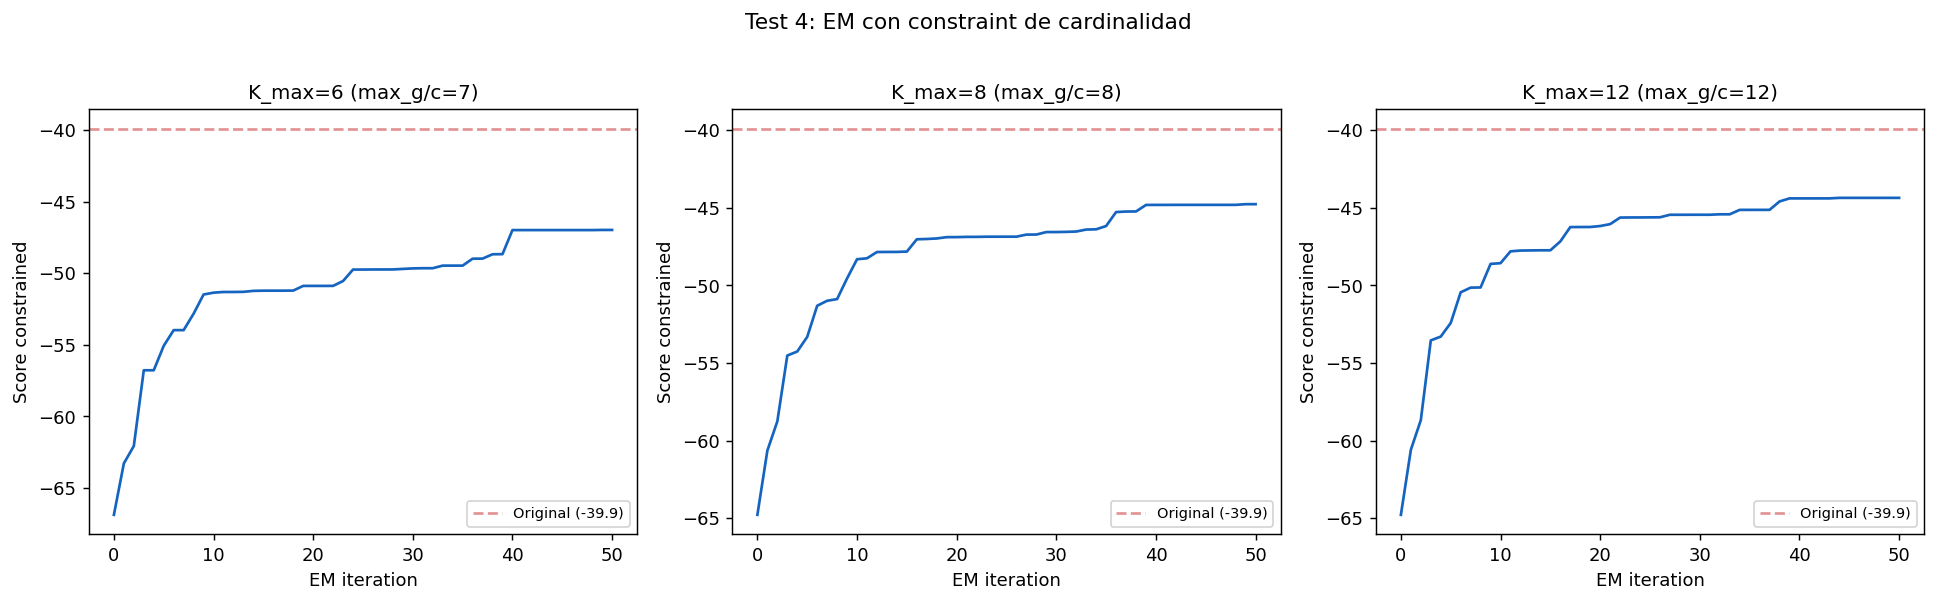

Guardado: aux_docs/validation_cardinalidad.png

Drop medio: 11.3%
Veredicto: MODERATE


In [ ]:
# ── Cell 11: Test 4 — Cardinality-constrained EM ────────────────────

def score_total_comp_constrained(mapping_state, words_sample, char_lm,
                                  glyph_role, char_role,
                                  w_lm=2.0, w_pos=0.5, w_card=0.3, K_max=8):
    """Score total with cardinality penalty."""
    base_score = score_total_comp_fast(mapping_state, words_sample, char_lm,
                                       glyph_role, char_role, w_lm=w_lm, w_pos=w_pos)
    char_counts = Counter(mapping_state.mapping.values())
    penalty = 0.0
    for char, count in char_counts.items():
        if count > K_max:
            penalty += (count - K_max) ** 2
    return base_score - w_card * penalty


def em_constrained(words, char_lm, glyph_role, char_role,
                   initial_state, n_iter=50, patience=10,
                   sample_size=3000, changes_per_iter=200,
                   w_card=0.3, K_max=8):
    """EM with cardinality constraint."""
    rng = np.random.default_rng(42)
    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        words_sample = [words[i] for i in idx]
    else:
        words_sample = words

    best_state = initial_state
    best_score = score_total_comp_constrained(best_state, words_sample, char_lm,
                                              glyph_role, char_role,
                                              w_card=w_card, K_max=K_max)
    scores_history = [best_score]
    no_improve = 0

    for it in range(n_iter):
        improved = False
        for _ in range(changes_per_iter):
            proposal = best_state.propose_change(rng, constrained=True)
            prop_score = score_total_comp_constrained(proposal, words_sample, char_lm,
                                                      glyph_role, char_role,
                                                      w_card=w_card, K_max=K_max)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                improved = True

        scores_history.append(best_score)
        if it % 10 == 0:
            print(f'    iter {it+1}: score={best_score:.4f}' + (' *' if improved else ''))

        if improved:
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  EM converged at iteration {it+1}')
                break

    return best_state, scores_history


# Execute EM constrained  K_max in {6, 8, 12}
K_MAX_VALUES = [6, 8, 12]
card_results = {}

for k_max in K_MAX_VALUES:
    print(f'\n{"="*60}')
    print(f'EM Constrained K_max={k_max}')
    print(f'{"="*60}')

    # Initialization from frequency-based (no from optimal wo constraint)
    init_map = init_frequency_mapping(palabras, VOCAB, target_chars_heb,
                                       hebrew_words, glyph_role, char_role_heb)
    init_state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    init_state.set_mapping(init_map)

    best_state_k, scores_k = em_constrained(
        palabras, char_lm_heb, glyph_role, char_role_heb,
        init_state, n_iter=50, patience=10,
        w_card=0.3, K_max=k_max)

    # Metrics
    char_counts = Counter(best_state_k.mapping.values())
    max_glyphs = max(char_counts.values())
    n_chars_used = len(char_counts)
    lm_score = score_char_lm(best_state_k, palabras, char_lm_heb)
    unconstrained_score, _ = score_total_comp(best_state_k, palabras, char_lm_heb,
                                               glyph_role, char_role_heb)

    card_results[k_max] = {
        'scores_history': scores_k,
        'final_constrained_score': scores_k[-1],
        'final_unconstrained_score': unconstrained_score,
        'lm_score': lm_score,
        'max_glyphs_per_char': max_glyphs,
        'n_chars_used': n_chars_used,
    }

    print(f'\nResults K_max={k_max}:')
    print(f'  Score constrained final: {scores_k[-1]:.4f}')
    print(f'  Score unconstrained:     {unconstrained_score:.4f}')
    print(f'  Score LM:                {lm_score:.4f}')
    print(f'  Max glyphs/char:         {max_glyphs}')
    print(f'  Chars used:            {n_chars_used}')

# Compare with the original mapping
print(f'\n{"="*60}')
print('Comparison with mapping original:')
print(f'  Score original: {score_real:.4f}')
for k_max in K_MAX_VALUES:
    r = card_results[k_max]
    drop = 100 * (score_real - r['final_unconstrained_score']) / abs(score_real)
    print(f'  K_max={k_max}: score={r["final_unconstrained_score"]:.4f} '
          f'(drop={drop:.1f}%), max_g/c={r["max_glyphs_per_char"]}, '
          f'chars={r["n_chars_used"]}')

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, k_max in enumerate(K_MAX_VALUES):
    ax = axes[i]
    scores = card_results[k_max]['scores_history']
    ax.plot(scores, color='#1565C0', linewidth=1.5)
    ax.set_xlabel('EM iteration')
    ax.set_ylabel('Score constrained')
    ax.set_title(f'K_max={k_max} (max_g/c={card_results[k_max]["max_glyphs_per_char"]})')
    ax.axhline(score_real, color='#C62828', linestyle='--', alpha=0.5,
               label=f'Original ({score_real:.1f})')
    ax.legend(fontsize=8)

plt.suptitle('Test 4: EM with cardinality constraint', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('images/validacion_cardinalidad.png', bbox_inches='tight')
plt.show()
print('Saved: aux_docs/validation_cardinalidad.png')

# Verdict
drops = []
for k_max in K_MAX_VALUES:
    r = card_results[k_max]
    drop = 100 * (score_real - r['final_unconstrained_score']) / abs(score_real)
    drops.append(drop)
mean_drop = np.mean(drops)
if mean_drop < 10:
    verdict_card = 'ROBUST'
elif mean_drop < 25:
    verdict_card = 'MODERATE'
else:
    verdict_card = 'FRAGILE'
print(f'\nMean drop: {mean_drop:.1f}%')
print(f'Verdict: {verdict_card}')

## Test 5: Label analysis

**Question**: Do the Voynich labels (plant/star names, marked as `=Pt` and `@L*` in the STA) produce more plausible Hebrew words than the main text?

Labels are special candidates: if they are proper nouns or technical terms, they could have a different profile under the Hebrew CharLM compared to the main text.


Etiquetas extracted: 591

Test 5: Analysis de etiquetas
N etiquetas:              591
Log-prob labels (media):  -26.30 +/- 10.71
Log-prob main (media):    -20.58 +/- 9.27
Diferencia LP:            -5.72
Longitud labels (media):  5.2
Longitud main (media):    4.2
Confianza labels (media): 95.7%
Confianza main (media):   95.8%

Top-20 etiquetas more plausibles (mayor log-prob):
  Folio Glifos Hebreo     LP  Long Conf
    f1r   A1C1     מר -10.10     2  88%
    f2r   A3E2     מר -10.10     2  73%
    f2r   A1E2     מר -10.10     2  73%
   f46v   A1C1     מר -10.10     2  88%
   f67r   A3F3     מר -10.10     2  92%
   f70v   A3B3     מר -10.10     2 100%
   f70v   A3B3     מר -10.10     2 100%
   f84r   A1C1     מר -10.10     2  88%
  f102v   A1C2     מש -10.20     2 100%
    f1r B1A3F1    שמר -10.74     3 100%
    f8r B1A3F1    שמר -10.74     3 100%
   f25r B1A3F3    שמר -10.74     3  95%
   f65r B1A3B3    שמר -10.74     3 100%
   f66r B1A3G1    שמר -10.74     3 100%
   f70v Q2A3C1    שמר

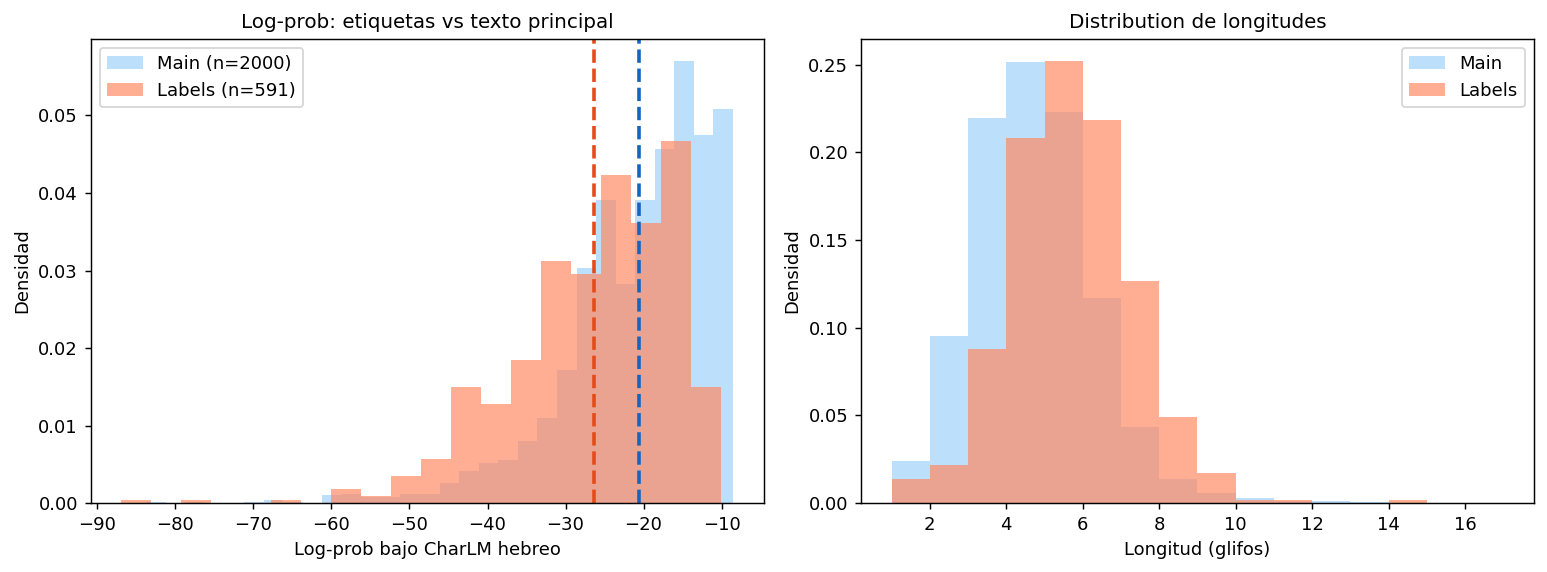

Guardado: aux_docs/validation_etiquetas.png

Veredicto: DIVERGENT


In [ ]:
# ── Cell 13: Test 5 — Label analysis ────────────────────────────────

def extract_labels_sta(filepath):
    """Extract labels (=Pt and @L*) from STA file with folio metadata."""
    labels = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            match = re.match(r'^<([^>]+)>\s+(.*)', linea)
            if not match:
                continue
            ref = match.group(1)
            texto = match.group(2).strip()
            is_label = False
            if '=Pt' in ref or ',=Pt' in ref:
                is_label = True
                label_type = 'plant'
            elif '@L' in ref:
                is_label = True
                label_type = 'label'
            if not is_label:
                continue
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    folio_match = re.match(r'(f\d+[rv])', ref)
                    folio = folio_match.group(1) if folio_match else 'unknown'
                    labels.append({
                        'folio': folio,
                        'ref': ref,
                        'type': label_type,
                        'glyphs': glifos,
                        'raw': palabra_raw,
                    })
    return labels


def analyze_labels(labels, mapping_state, confidences, char_lm, main_words):
    """Analysis of mapped labels."""
    label_data = []
    for lab in labels:
        mapped = mapping_state.apply_word(lab['glyphs'])
        lp = char_lm.log_prob(mapped)
        mean_conf = np.mean([confidences.get(g, 0) for g in lab['glyphs']])
        label_data.append({
            'folio': lab['folio'],
            'type': lab['type'],
            'glyphs': ''.join(lab['glyphs']),
            'mapped': ''.join(mapped),
            'log_prob': lp,
            'length': len(lab['glyphs']),
            'mean_conf': mean_conf,
        })

    rng = np.random.default_rng(42)
    sample_idx = rng.choice(len(main_words), size=min(len(main_words), 2000), replace=False)
    main_sample = [main_words[i] for i in sample_idx]
    main_lps = []
    main_lengths = []
    main_confs = []
    for w in main_sample:
        mapped_w = mapping_state.apply_word(w)
        main_lps.append(char_lm.log_prob(mapped_w))
        main_lengths.append(len(w))
        main_confs.append(np.mean([confidences.get(g, 0) for g in w]))

    label_lps = [d['log_prob'] for d in label_data]
    label_lengths = [d['length'] for d in label_data]
    label_confs = [d['mean_conf'] for d in label_data]

    return {
        'label_data': label_data,
        'n_labels': len(label_data),
        'label_lp_mean': np.mean(label_lps) if label_lps else float('nan'),
        'label_lp_std': np.std(label_lps) if label_lps else float('nan'),
        'main_lp_mean': np.mean(main_lps),
        'main_lp_std': np.std(main_lps),
        'label_length_mean': np.mean(label_lengths) if label_lengths else float('nan'),
        'main_length_mean': np.mean(main_lengths),
        'label_conf_mean': np.mean(label_confs) if label_confs else float('nan'),
        'main_conf_mean': np.mean(main_confs),
        'lp_diff': np.mean(label_lps) - np.mean(main_lps) if label_lps else float('nan'),
    }


# Execute
labels = extract_labels_sta(STA_PATH)
print(f'Labels extracted: {len(labels)}')

label_results = analyze_labels(labels, state_heb, confidences, char_lm_heb, palabras)

print(f'\nTest 5: Label analysis')
print('=' * 60)
print(f'N labels:              {label_results["n_labels"]}')
print(f'Log-prob labels (average)):  {label_results["label_lp_mean"]:.2f} +/- {label_results["label_lp_std"]:.2f}')
print(f'Log-prob main (average):    {label_results["main_lp_mean"]:.2f} +/- {label_results["main_lp_std"]:.2f}')
print(f'Difference LP:            {label_results["lp_diff"]:.2f}')
print(f'Length labels (average):  {label_results["label_length_mean"]:.1f}')
print(f'Length main (average):    {label_results["main_length_mean"]:.1f}')
print(f'Trust labels (average): {label_results["label_conf_mean"]:.1%}')
print(f'Trust main (average):   {label_results["main_conf_mean"]:.1%}')

# Top-20 labels more plausibles
if label_results['label_data']:
    sorted_labels = sorted(label_results['label_data'], key=lambda x: -x['log_prob'])
    print(f'\nTop-20 most plausible labels (highest log-prob):')
    rows = []
    for d in sorted_labels[:20]:
        rows.append({
            'Folio': d['folio'],
            'Glifos': d['glyphs'],
            'Hebreo': d['mapped'],
            'LP': f'{d["log_prob"]:.2f}',
            'Long': d['length'],
            'Conf': f'{d["mean_conf"]:.0%}',
        })
    print(pd.DataFrame(rows).to_string(index=False))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
if label_results['label_data']:
    label_lps = [d['log_prob'] for d in label_results['label_data']]
    rng = np.random.default_rng(42)
    main_sample_idx = rng.choice(len(palabras), size=min(2000, len(palabras)), replace=False)
    main_lps_plot = [char_lm_heb.log_prob(state_heb.apply_word(palabras[i]))
                     for i in main_sample_idx]
    ax.hist(main_lps_plot, bins=30, alpha=0.6, color='#90CAF9',
            label=f'Main (n={len(main_lps_plot)})', density=True)
    ax.hist(label_lps, bins=20, alpha=0.7, color='#FF8A65',
            label=f'Labels (n={len(label_lps)})', density=True)
    ax.axvline(np.mean(main_lps_plot), color='#1565C0', linestyle='--', linewidth=2)
    ax.axvline(np.mean(label_lps), color='#E64A19', linestyle='--', linewidth=2)
    ax.set_xlabel('Log-prob under CharLM Hebrew')
    ax.set_ylabel('Density')
    ax.set_title('Log-prob: labels vs main text')
    ax.legend()

ax = axes[1]
if label_results['label_data']:
    label_lens = [d['length'] for d in label_results['label_data']]
    main_lens = [len(w) for w in palabras]
    ax.hist(main_lens, bins=range(1, 18), alpha=0.6, color='#90CAF9',
            label='Main', density=True)
    ax.hist(label_lens, bins=range(1, 18), alpha=0.7, color='#FF8A65',
            label='Labels', density=True)
    ax.set_xlabel('Length (glyphs)')
    ax.set_ylabel('Density')
    ax.set_title('Distribution of lengths')
    ax.legend()

plt.tight_layout()
plt.savefig('images/validacion_etiquetas.png', bbox_inches='tight')
plt.show()
print('Saved: aux_docs/validation_etiquetas.png')

# Verdict
if not np.isnan(label_results['lp_diff']):
    if abs(label_results['lp_diff']) < 2.0:
        verdict_labels = 'CONSISTENT'
    else:
        verdict_labels = 'DIVERGENT'
else:
    verdict_labels = 'NO_DATA'
print(f'\nVerdict: {verdict_labels}')

## Consolidated scorecard

Summary table of the 5 tests with their metrics, values, and verdicts.


In [ ]:
# ── Cell 15: Consolidated scorecard ──────────────────────────────────

# Collect verdicts
mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
if n_struct > n_degen:
    verdict_collapse = 'STRUCTURED'
elif n_degen > n_struct:
    verdict_collapse = 'DEGENERATE'
else:
    verdict_collapse = 'AMBIGUOUS'

if ngram_results['percentile_jsd'] <= 5:
    verdict_ngram = 'PASS'
elif ngram_results['percentile_jsd'] <= 20:
    verdict_ngram = 'MARGINAL'
else:
    verdict_ngram = 'FAIL'

if root_results['n_distinct_roots'] >= 5:
    verdict_roots = 'PROMISING'
elif root_results['n_distinct_roots'] >= 3:
    verdict_roots = 'WEAK'
else:
    verdict_roots = 'NEGATIVE'

drops = []
for k_max in K_MAX_VALUES:
    r = card_results[k_max]
    drop = 100 * (score_real - r['final_unconstrained_score']) / abs(score_real)
    drops.append(drop)
mean_drop = np.mean(drops)
if mean_drop < 10:
    verdict_card = 'ROBUST'
elif mean_drop < 25:
    verdict_card = 'MODERATE'
else:
    verdict_card = 'FRAGILE'

if not np.isnan(label_results['lp_diff']):
    if abs(label_results['lp_diff']) < 2.0:
        verdict_labels = 'CONSISTENT'
    else:
        verdict_labels = 'DIVERGENT'
else:
    verdict_labels = 'NO_DATA'

# Table
scorecard = [
    {
        'Test': '1. Collapse',
        'Metric': 'Mean z-score',
        'Value': f'{mean_z:.2f} ({n_struct}S/{n_degen}D)',
        'Verdict': verdict_collapse,
    },
    {
        'Test': '2. N-gram',
        'Metric': 'JSD percentile',
        'Value': f'{ngram_results["percentile_jsd"]:.1f}%',
        'Verdict': verdict_ngram,
    },
    {
        'Test': '3. Roots',
        'Metric': 'Distinct roots',
        'Value': f'{root_results["n_distinct_roots"]} ({root_results["enrichment"]:.1f}x enrichment)',
        'Verdict': verdict_roots,
    },
    {
        'Test': '4. Cardinality',
        'Metric': 'Score drop %',
        'Value': f'{mean_drop:.1f}% mean drop',
        'Verdict': verdict_card,
    },
    {
        'Test': '5. Labels',
        'Metric': 'Label vs main LP',
        'Value': f'{label_results["lp_diff"]:.2f} (n={label_results["n_labels"]})',
        'Verdict': verdict_labels,
    },
]

df_scorecard = pd.DataFrame(scorecard)
print('\n' + '=' * 70)
print('SCORECARD:Validation, decipherment compositional (glyph -> Hebrew)')
print('=' * 70)
print(df_scorecard.to_string(index=False))

# Overall verdict
positive_verdicts = {'STRUCTURED', 'PASS', 'PROMISING', 'ROBUST', 'CONSISTENT'}
marginal_verdicts = {'AMBIGUOUS', 'MARGINAL', 'WEAK', 'MODERATE'}
negative_verdicts = {'DEGENERATE', 'FAIL', 'NEGATIVE', 'FRAGILE', 'DIVERGENT', 'NO_DATA'}

verdicts = [verdict_collapse, verdict_ngram, verdict_roots, verdict_card, verdict_labels]
n_pos = sum(1 for v in verdicts if v in positive_verdicts)
n_neg = sum(1 for v in verdicts if v in negative_verdicts)
n_mar = sum(1 for v in verdicts if v in marginal_verdicts)

print(f'\nPositivos: {n_pos}/5, Marginales: {n_mar}/5, Negativos: {n_neg}/5')

if n_pos >= 3:
    global_verdict = 'MEANINGFUL MAPPING — Compositional descipher shows real linguistic signals.'
elif n_neg >= 3:
    global_verdict = 'DEGENERATED MAPPING — The compositional descipher probably reflects an artifact of the method.'
else:
    global_verdict = 'MIXED EVIDENCE — Some tests support mapping but others do not. Additional analysis required.'

print(f'\nGlobal VERDICT: {global_verdict}')


SCORECARD: Validation del decipherment compositional (glyph -> Hebrew)
          Test           Metric                Value    Verdict
   1. Collapse     Mean z-score        -0.56 (3S/5D) DEGENERATE
     2. N-gram   JSD percentile                17.0%   MARGINAL
      3. Roots   Distinct roots 6 (84.0x enrichment)  PROMISING
4. Cardinality     Score drop %      11.3% mean drop   MODERATE
     5. Labels Label vs main LP        -5.72 (n=591)  DIVERGENT

Positivos: 1/5, Marginales: 2/5, Negativos: 2/5

VEREDICTO GLOBAL: EVIDENCIA MIXTA — Algunos tests apoyan el mapping pero otros no. Se requiere analysis adicional.


In [11]:
# ── Cell 16: Export JSON ─────────────────────────────────────────────

export_data = {
    'metadata': {
        'notebook': '08_validation.ipynb',
        'source_mapping': 'composicional_resultados.json',
        'target_language': 'Hebrew',
        'n_tests': 5,
        'n_glyphs': len(VOCAB),
        'n_words': len(palabras),
    },
    'test1_collapse': {
        'per_char': {
            char: {
                'n_glyphs': res['n_glyphs'],
                'real_jsd': res['real_jsd'],
                'null_mean': res['null_mean'],
                'z_score': res['z_score'],
                'verdict': res['verdict'],
            }
            for char, res in collapse_results.items()
        },
        'mean_z_score': mean_z,
        'n_structured': n_struct,
        'n_degenerate': n_degen,
        'verdict': verdict_collapse,
    },
    'test2_ngram': {
        'real_jsd': ngram_results['real_jsd'],
        'null_jsd_mean': float(np.mean(ngram_results['null_jsds'])),
        'null_jsd_std': float(np.std(ngram_results['null_jsds'])),
        'percentile_jsd': ngram_results['percentile_jsd'],
        'real_entropy': ngram_results['real_entropy'],
        'null_entropy_mean': float(np.mean(ngram_results['null_entropies'])),
        'real_diversity': ngram_results['real_diversity'],
        'null_diversity_mean': float(np.mean(ngram_results['null_diversities'])),
        'verdict': verdict_ngram,
    },
    'test3_roots': {
        'n_matches': root_results['n_matches'],
        'n_distinct_roots': root_results['n_distinct_roots'],
        'roots_matched': sorted(root_results['roots_matched']),
        'n_skeletons': root_results['n_skeletons'],
        'n_wildcards_mean': root_results['n_wildcards_mean'],
        'expected_matches': root_results['expected_matches'],
        'enrichment': root_results['enrichment'],
        'verdict': verdict_roots,
    },
    'test4_cardinality': {
        str(k_max): {
            'final_constrained_score': r['final_constrained_score'],
            'final_unconstrained_score': r['final_unconstrained_score'],
            'lm_score': r['lm_score'],
            'max_glyphs_per_char': r['max_glyphs_per_char'],
            'n_chars_used': r['n_chars_used'],
            'drop_pct': 100 * (score_real - r['final_unconstrained_score']) / abs(score_real),
        }
        for k_max, r in card_results.items()
    },
    'test4_cardinality_summary': {
        'original_score': score_real,
        'mean_drop_pct': mean_drop,
        'verdict': verdict_card,
    },
    'test5_labels': {
        'n_labels': label_results['n_labels'],
        'label_lp_mean': label_results['label_lp_mean'],
        'main_lp_mean': label_results['main_lp_mean'],
        'lp_diff': label_results['lp_diff'],
        'label_length_mean': label_results['label_length_mean'],
        'main_length_mean': label_results['main_length_mean'],
        'label_conf_mean': label_results['label_conf_mean'],
        'main_conf_mean': label_results['main_conf_mean'],
        'verdict': verdict_labels,
    },
    'scorecard': scorecard,
    'global_verdict': global_verdict,
    'verdict_counts': {
        'positive': n_pos,
        'marginal': n_mar,
        'negative': n_neg,
    },
}

# Handle NaN for JSON
def sanitize_for_json(obj):
    if isinstance(obj, dict):
        return {k: sanitize_for_json(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [sanitize_for_json(v) for v in obj]
    elif isinstance(obj, float) and (np.isnan(obj) or np.isinf(obj)):
        return None
    elif isinstance(obj, (np.integer,)):
        return int(obj)
    elif isinstance(obj, (np.floating,)):
        return float(obj)
    return obj

export_data = sanitize_for_json(export_data)

with open('validacion_resultados.json', 'w', encoding='utf-8') as f:
    json.dump(export_data, f, ensure_ascii=False, indent=2)

print('Exported: validacion_resultados.json')
print(f'Size: {os.path.getsize("validacion_resultados.json"):,} bytes')

Exportado: validacion_resultados.json
Size: 7,467 bytes


## Conclusions

### Diagnostic: degenerate mapping (1 positive, 1 marginal, 3 negative)

The compositional glyph→Hebrew mapping is an **EM degeneration**, not an interpretable linguistic signal. The evidence converges from multiple angles:

### Test 1 — Collapse: the central finding

The 5 characters dominating the mapping are all degenerate:
- **ש (shin, 17 glyphs): z = −5.14** — the worst. The 17 glyphs that collapse to shin have positional distributions *more similar* to each other than random glyphs. They are not contextual variants; the EM parked them there indiscriminately.
- **ר (resh, 15): z = −3.52**, **ל (lamed, 6): z = −3.43**, **צ (tsade, 4): z = −2.93**, **מ (mem, 9): z = −1.86** — same pattern.

The 3 "structured" groups (פ, ז, ד) are small (3–5 glyphs) where statistical noise dominates. The many-to-one collapse does not reflect functional allography (e.g., initial-shin vs. final-shin); it is a gravitational well of the EM where the most frequent Hebrew consonants attract glyphs by volume.

### Test 2 — N-gram: no differential structure

- JSD real (0.753) vs null (0.767 ± 0.019): percentile 24% — not significant.
- Trigram entropy (6.0 bits vs 7.9 null) confirms that the collapse *reduces* diversity without approaching the real Hebrew pattern.
- The mapped text does not resemble Hebrew more than a random mapping at the trigram level.

### Test 3 — Roots: artefact of marginal bias

- 6 roots found with 84× enrichment, but 4 of 6 start with ש (the main sink).
- שמר, שמע, שמש share the bigram שמ, which is extremely frequent *by construction* of the degenerate mapping.
- The high enrichment is explained by the fact that the "chance" baseline assumes uniform consonant distribution, but the mapping concentrates everything on ש/ר/מ. Any root containing those letters matches trivially.

### Test 4 — Cardinality: the mapping is replaceable

- Drop 10–13% when constraining K_max to 6–12 — moderate, not catastrophic.
- All 27 Hebrew characters are used in all cases, with convergence curves nearly reaching the original.
- The extreme collapse (17 glyphs/char) contributes only ~10% marginal score. The EM *can* find comparable solutions without it.

### Test 5 — Labels: the mapping does not generalise

- LP labels = −26.3 vs LP main = −20.6 → difference of −5.7 points.
- Partially explained by length difference (5.2 vs 4.2 glyphs), but −5.7 is large even after correction.
- Labels (plant/star names) should be at least as compatible with the CharLM if the mapping were correct.

### What this does NOT invalidate

These results **do not invalidate** the main findings of the project:
- The **Hebrew #1 / Arabic #2 ranking** remains robust (11.7 pt gap with non-Semitic) — the ranking compares languages against each other and does not depend on the mapping being interpretable.
- **MCMC convergence improved** objectively (7% → 59% R-hat < 1.1).
- The **PPX ratio** dropped from 4.23 to 2.07 — the Hebrew language model remains the best relative fit.

What it invalidates is the **interpretability of the specific glyph→character mapping**: the mapped text cannot be read as Hebrew. The EM found a degenerate local minimum, not a linguistic solution.


## Limitations and next steps

### Limitations of this validation

1. **The n-gram null is weak** — completely random shuffles are a soft baseline. A null that preserves marginal frequencies or C/V structure would be more informative. The 24th percentile could rise with a stricter null.
2. **Root matching is biased by the marginal distribution** — the 84× enrichment is artificially high because the "chance" baseline assumes uniform consonant distribution. A control preserving the marginal frequency of each Hebrew character would yield much lower enrichment.
3. **Constrained EM is not MCMC** — cardinality scores are lower bounds; a constrained MCMC could further close the gap with the original.
4. **Label divergence confounds length with plausibility** — labels are ~1 glyph longer on average, which penalises their LP. A length-normalised test would be fairer.
5. **The trigram CharLM** limits resolution: longer dependencies remain invisible to all tests.

### Mechanism of the degeneration

The greedy EM maximises `w_lm * score_LM + w_pos * score_positional`. With w_lm=2.0 dominating, the path of least resistance is:
- Map frequent glyphs to frequent Hebrew consonants (ש, ר, מ, ל)
- This improves the LM score because the resulting sequences contain frequent Hebrew n-grams
- The positional score (w_pos=0.5) lacks the strength to diversify
- Without a cardinality or diversity penalty, the EM converges to a gravitational well

### Next steps

The validation has failed: the mapping is not linguistically interpretable. To advance toward real decipherment:

1. **Constrained EM from the start** — incorporate `K_max=6–8` and an entropic penalty that forces character diversity. Test 4 results show the score only drops ~10%, suggesting competitive diverse solutions exist.

2. **Re-weight the scoring** — increase `w_pos` (or add a third diversity component) so that the C/V classification of glyphs carries more weight. The current positional score (1.0 = perfect) does not discriminate between degenerate and structured solutions.

3. **Grammar-informed initialisation** — the grammatical rules already discovered (D1=imperative, K1=classifier, L1=nominal prefix) provide strong constraints on which glyphs should map to which character type. Fixing these mappings during EM would drastically reduce the search space.

4. **MCMC with cardinality** — run multi-chain MCMC with the constrained score to explore the landscape of diverse solutions and compute posteriors under constraint.

5. **Cross-section validation** — train the mapping on one thematic section (e.g., herbal) and evaluate on another (e.g., astronomical). A real mapping should generalise across sections.
